<a href="https://colab.research.google.com/github/nuruyar/ai_master_computervision/blob/main/lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.ndimage as snd
from scipy.ndimage import *
from skimage import feature
import cv2
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


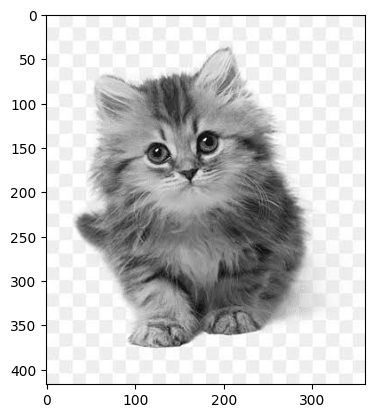

float64


In [ ]:
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im_gray = np.array(Image.open(path + "/kedi.jpeg").convert('L'), np.float64)
imgplot = plt.imshow(im_gray, cmap='gray')
plt.show()
print(str(im_gray.dtype))

**NORMAIZER**

In [ ]:
def maxmin_norm(I):
  min_image = min(I.flatten())
  Inorm = I-min_image
  max_image = max(Inorm.flatten())
  Inorm = Inorm/max_image
  Inorm = Inorm * 255
  return Inorm

**MORPHOLOGICAL FILTERING**

Number of objects: 108


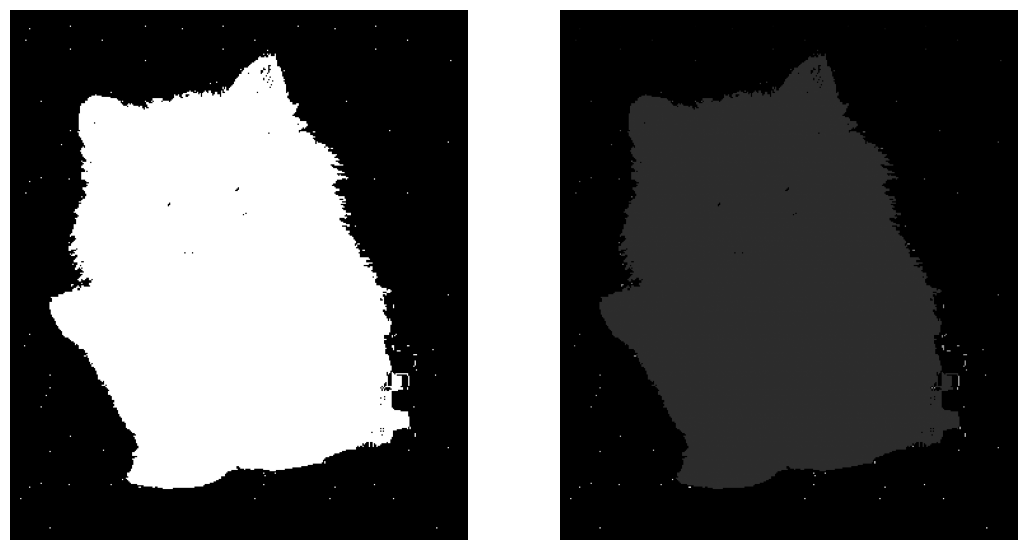

In [ ]:
im_bin = (im_gray <= 230)
labels, nbr_objects = snd.label(im_bin)
print ("Number of objects:", nbr_objects)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(13,13))
ax[0].imshow(maxmin_norm(np.uint8(im_bin)), cmap='gray')
ax[0].axis('off')
ax[1].imshow(maxmin_norm(labels), cmap='gray')
ax[1].axis('off')
plt.show()

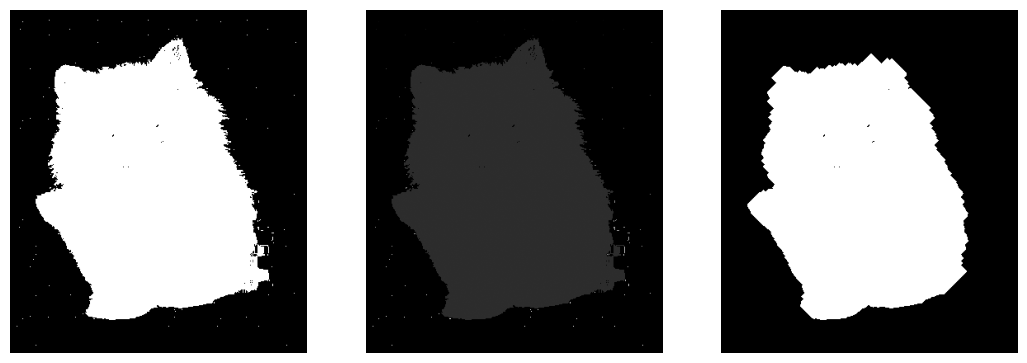

Number of objects: 1


In [ ]:
se = np.array([[0,0,1,0,0],[0,1,1,1,0],[1,1,1,1,1],[0,1,1,1,0],[0,0,1,0,0]])
im_opened = binary_opening(im_bin,se,iterations=7)
labels_cleaned, nbr_objects_cleaned = snd.label(im_opened)
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(13,13))
ax[0].imshow(maxmin_norm(np.uint8(im_bin)), cmap='gray')
ax[0].axis('off')
ax[1].imshow(maxmin_norm(labels), cmap='gray')
ax[1].axis('off')
ax[2].imshow(maxmin_norm(labels_cleaned), cmap='gray')
ax[2].axis('off')
plt.show()
print ("Number of objects:", nbr_objects_cleaned)